# Project 2: Housing Price Prediction – Pass 01

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

#### 2. Load Pandas, Numpy, and Matplotlib modules

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics

#### 3. Load data Train.csv from AWS S3.

In [2]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

- Read in the data from .csv using pandas:

In [3]:
# make dataframe
df = pd.read_csv( url )

- Check the dataframe:

In [4]:
# check dataframe
df

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



First, define the target column:

In [5]:
# define target_col
target_col = 'SalePrice'
target_col

'SalePrice'

- head

In [6]:
# head
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


- tail

In [7]:
# tail
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


- shape

In [8]:
# shape
df.shape

(2637, 81)

- size

In [9]:
# size
df.size

213597

- info

In [10]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

- describe

In [11]:
# describe
df.describe()

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2.637000e+03,2637.000000,2188.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2614.000000,2636.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,7.141301e+08,57.349261,69.166819,10044.694729,6.097459,5.569966,1971.288586,1984.202882,101.887911,438.441199,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,1.887527e+08,42.499091,23.356779,6742.549521,1.411522,1.118262,30.306986,20.913077,179.578232,449.602326,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,5.284770e+08,20.000000,58.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,5.354530e+08,50.000000,68.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,9.071870e+08,70.000000,80.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,732.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,1.007100e+09,190.000000,313.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


- nunique

In [12]:
# nunique
df.nunique().sort_values( ascending = False )

,0
PID,2637
Lot Area,1799
Gr Liv Area,1216
Bsmt Unf SF,1080
1st Flr SF,1022
...,...
Bsmt Half Bath,3
Paved Drive,3
Street,2
Alley,2


In [13]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Bsmt Half Bath,0.113766
Paved Drive,0.113766
Street,0.075844
Alley,0.075844


- unique

In [14]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [15]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


In [16]:
df[['Lot Frontage', target_col]].isnull().sum()

,0
Lot Frontage,449
SalePrice,0


In [17]:
# isnull frequencies
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
...,...
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000
Sale Condition,0.000000


In [18]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([9.95828593e+01, 9.63594994e+01, 9.31740614e+01, 7.99772469e+01,
       6.09404626e+01, 4.86916951e+01, 1.70269245e+01, 5.57451650e+00,
       5.49867273e+00, 2.88206295e+00, 2.80621919e+00, 2.76829731e+00,
       8.72203261e-01, 7.58437619e-02, 3.79218809e-02, 0.00000000e+00])

In [19]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).value_counts()

,count
0.000000,55
0.037922,6
5.574516,4
2.768297,3
0.075844,2
99.582859,1
93.174061,1
96.359499,1
17.026925,1
48.691695,1


In [20]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum()).sort_values( ascending = False )).value_counts().sort_index()

,count
0,55
1,6
2,2
23,1
73,3
74,1
76,1
145,1
147,4
449,1


Many different null counts exist throughout the data set, indicating that this will not be a straightforward nulls cleanup.

- dtypes

In [21]:
# dtypes
df.dtypes

,0
PID,int64
MS SubClass,int64
MS Zoning,object
Lot Frontage,float64
Lot Area,int64
...,...
Mo Sold,int64
Yr Sold,int64
Sale Type,object
Sale Condition,object


In [22]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(14208)

#### Target: Value Counts

In [23]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [24]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [25]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [26]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

There are no nulls in the target column, which means no rows will need to be dropped on its account.

In [27]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

In [28]:
# view number of null again
df.isnull().sum()

,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,449
Lot Area,0
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


In [29]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [30]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [31]:
# show columns with non-null values
df.isnull().sum()[df.isnull().sum() != df.shape[0]]

,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,449
Lot Area,0
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


In [32]:
# count these
int(df.isnull().sum()[df.isnull().sum() != df.shape[0]].count())

81

In [33]:
# show only features
df.isnull().sum()[df.isnull().sum() != df.shape[0]][1:-1]

,0
MS SubClass,0
MS Zoning,0
Lot Frontage,449
Lot Area,0
Street,0
...,...
Misc Val,0
Mo Sold,0
Yr Sold,0
Sale Type,0


In [34]:
# count these
int(df.isnull().sum()[df.isnull().sum() != df.shape[0]][1:-1].count())

79

In [35]:
# make list of columns with all nulls
list_nulls = list(df.isnull().sum()[df.isnull().sum() == df.shape[0]].keys())
print(list_nulls, end = " ")

[] 

In [36]:
# count the number of list items (should match count of null cols above)
len(list_nulls)

0

In [37]:
# make list of columns with no nulls
list_nulls = list(df.isnull().sum()[df.isnull().sum() == df.shape[0]].keys())
print(list_nulls, end = " ")

[] 

In [38]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Area,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0


In [39]:
# columns with one or more nulls
df.isnull().sum()[df.isnull().sum() != 0]

,0
Lot Frontage,449
Alley,2457
Mas Vnr Type,1607
Mas Vnr Area,23
Bsmt Qual,73
Bsmt Cond,73
Bsmt Exposure,76
BsmtFin Type 1,73
BsmtFin SF 1,1
BsmtFin Type 2,74


Summary:

The dataset contains 2637 rows and 81 columns, making for a total of 213597 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: [ 'Lot Frontage' ]
  - identifier columns: 'PID'
  - null columns: 0
  - null rows (target): 0

- non-null rows: ?

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [40]:
# head again to double-check
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [41]:
# 1. 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped; target and var_0 - var_11 will be kept
# 2. 8314 null target rows should be dropped
# 3. 6 null feature columns should be dropped
# 4. After this, drop rows for any column with low null count
# 5. Finally, impute remaining nulls with column medians

1. Remove identifier columns

In [42]:
# make backup
df_bak = df.copy()
df_bak

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000


In [43]:
# restore from backup
df = df_bak.copy()
df

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000


In [44]:
target_col = 'SalePrice'
feature_cols = [ 'Lot Frontage' ]
target_col, feature_cols

('SalePrice', ['Lot Frontage'])

In [45]:
# keep the target and all features
# df = df.drop( columns = [ x for x in df.columns if x not in [target_col] + feature_cols ] )

In [46]:
# keep the target and all features
df = df[[target_col] + feature_cols]

In [47]:
# check our dataframe (display transformed df)
df

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2632,114500,52.0
2633,162000,74.0
2634,211500,61.0
2635,165000,78.0


2. Drop null target rows



3. Drop feature columns with all nulls

4. Drop remaining records with null counts (if few)

5.  impute with the median for remaining fields

In [48]:
# backup 2
df_bak2 = df.copy()
df_bak2

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2632,114500,52.0
2633,162000,74.0
2634,211500,61.0
2635,165000,78.0


In [49]:
# restore from backup 2
df = df_bak2.copy()
df

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2632,114500,52.0
2633,162000,74.0
2634,211500,61.0
2635,165000,78.0


In [50]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
SalePrice,0


In [51]:
# normalize null counts (;er column)
df.isnull().sum().sort_values( ascending = False ) / df.shape[0] * 100

,0
Lot Frontage,17.026925
SalePrice,0.000000


In [52]:
# preview filtering rows for where target is not null
df.loc[df[target_col].isnull() == False]

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2632,114500,52.0
2633,162000,74.0
2634,211500,61.0
2635,165000,78.0


Impute:

In [53]:
# loop through features to bulk impute with respective column medians
for feature_col in feature_cols:

  # Calculate the median
  median = df[feature_col].median()
  display(median)

  # Assign median to nulls
  df.fillna( {feature_col: median}, inplace = True )

  # Verify median is about the same as before
  display(df[feature_col].median())

68.0

68.0

In [54]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
SalePrice,0
Lot Frontage,0


In [55]:
# backup 3
df_bak3 = df.copy()
df_bak3

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2632,114500,52.0
2633,162000,74.0
2634,211500,61.0
2635,165000,78.0


In [56]:
# restore from backup
df = df_bak3.copy()
df

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2632,114500,52.0
2633,162000,74.0
2634,211500,61.0
2635,165000,78.0


In [57]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

## Exploratory Data Analysis


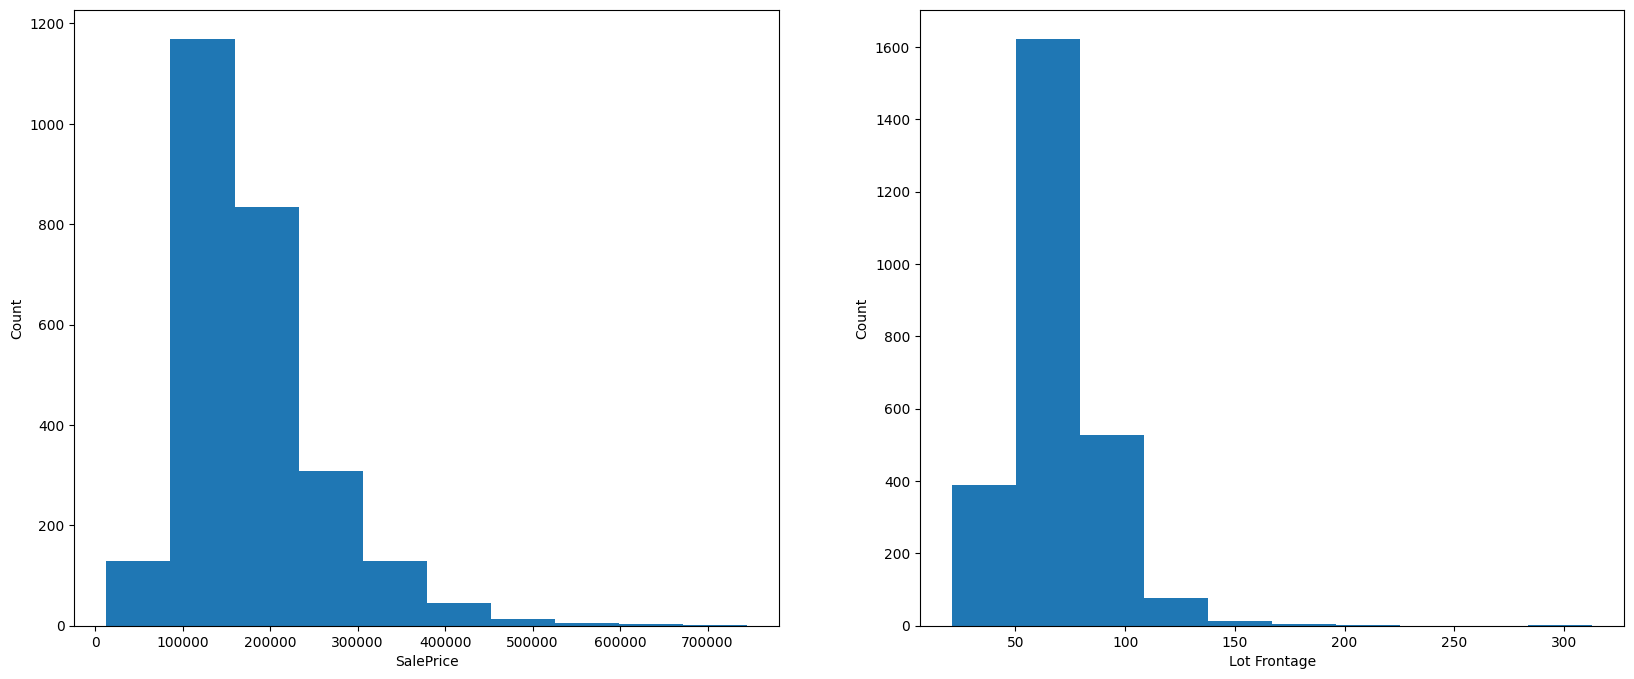

In [77]:
# Let's plot mpg and all of our predictors
fig, subplot = plt.subplots(1,2, figsize = (20,8)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = df.columns
n = 0
for i in range(2): # Loop through rows
  # for j in range(2): # Loop through columns
    subplot[i].hist(df[column_names[n]])
    subplot[i].set_xlabel(column_names[n])
    subplot[i].set_ylabel('Count')
    n = n + 1

### What do we notice?

- SalePrice and Lot Frontage are positively skewed
- Perhaps some outliers

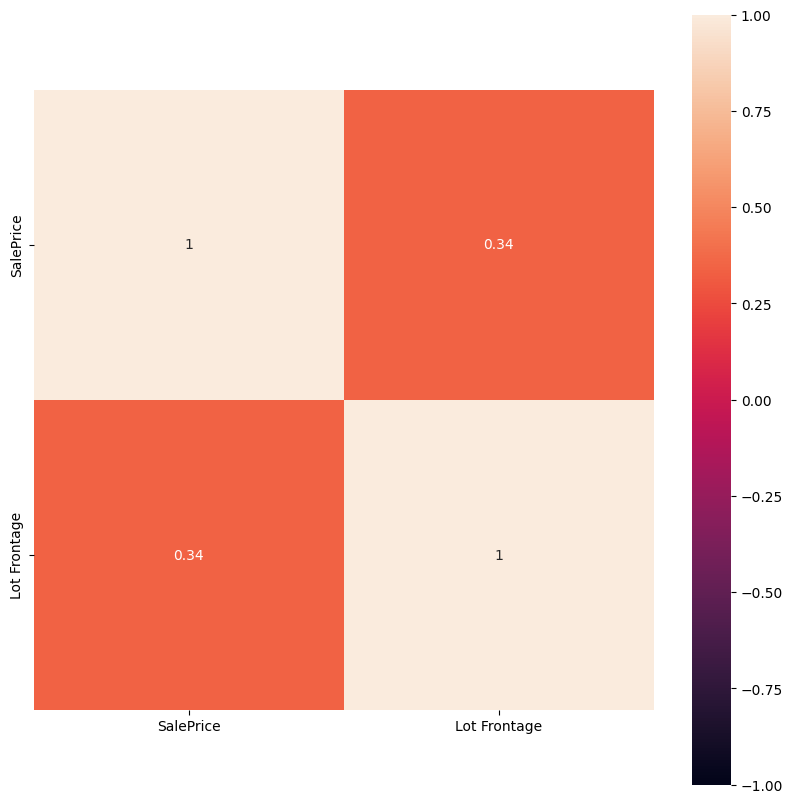

In [65]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=-1, vmax=1, square=True) ;



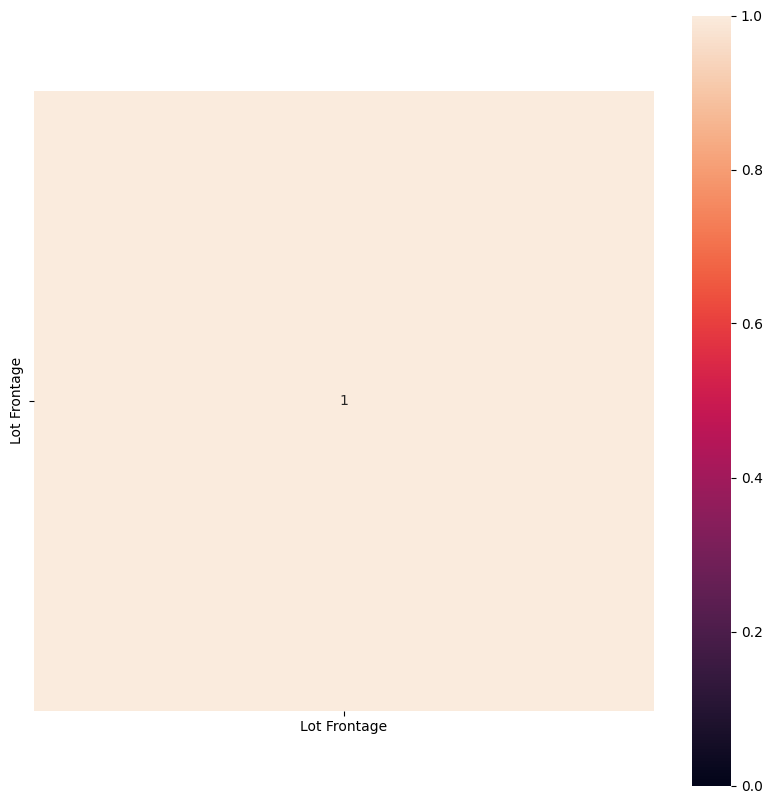

In [70]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=0, vmax=1, square=True) ;



In [72]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Lot Frontage,0.34


<Axes: >

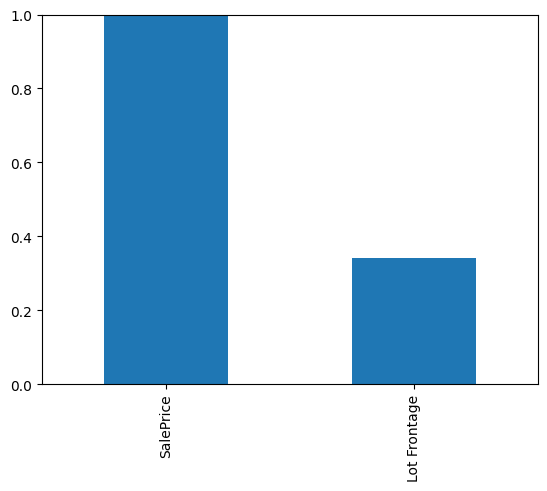

In [71]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [73]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()




,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,Lot Frontage,0.34
2,Lot Frontage,SalePrice,0.34
3,Lot Frontage,Lot Frontage,1.00


In [74]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,Lot Frontage,0.34
1,Lot Frontage,SalePrice,0.34


In [75]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,SalePrice,Lot Frontage,0.34
1,Lot Frontage,SalePrice,0.34


In [76]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,SalePrice,Lot Frontage,0.34


### What do we notice?

- SalePrice vs. Lot Frontage do not appear to be highly correlated to each other

In [67]:
df.size

5274

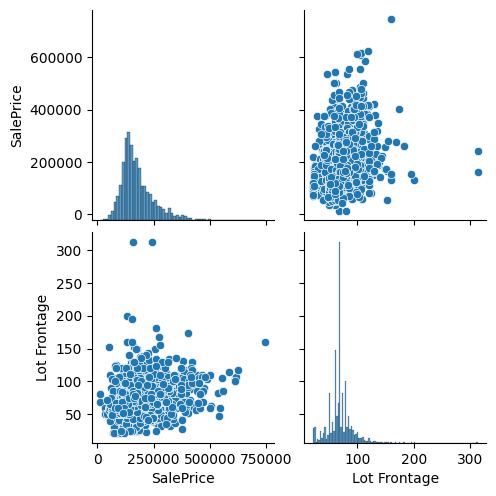

In [69]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- SalePrice vs. Lot Frontage is rather scattered, and does not appear to be linear.

## Processing



## Data Visualization/Communication of Results
